# Lesson 17 — Outbreak Surveillance Analytics with OLAP SQL

**Objective:** Turn a case line list into surveillance indicators using analytical (OLAP) SQL: a star schema, data-quality checks, daily epidemic curves with 7-day moving averages, district-by-week roll-ups, attack rates per 100,000, week-over-week growth and reporting delays, presented as a surveillance dashboard.

**Engine:** DuckDB, an embedded columnar OLAP database. The SQL patterns used here (window functions, `ROLLUP`/`CUBE`, date bucketing, `LAG`) carry over to cloud warehouses such as ClickHouse and Snowflake; a dialect comparison is given at the end.

**Data:** A synthetic outbreak line list for a fictional region of 8 districts (March–July 2025), generated with a fixed random seed. It deliberately includes common surveillance data problems: reporting delays, weekend reporting dips, duplicate reports, data-entry errors and incomplete recent days. No real patient data is used.

In [1]:
# Lesson 17 — Step 1: Generate a synthetic outbreak line list and save it as warehouse files
import numpy as np
import pandas as pd
import duckdb
from pathlib import Path

rng = np.random.default_rng(42)

# --- Study period and data extract date ---
start, end = pd.Timestamp("2025-03-03"), pd.Timestamp("2025-07-20")
extract_date = end                      # the day the data was pulled from the system
days = pd.date_range(start, end, freq="D")
t = np.arange(len(days))

# --- Fictional districts: population, outbreak size, peak timing and width ---
districts = pd.DataFrame({
    "district_id": range(1, 9),
    "district":   ["Central", "Lakeside", "North Ridge", "Eastvale",
                   "Riverbend", "Hillcrest", "Westfield", "Southport"],
    "province":   ["Urban", "Urban", "Northern", "Eastern",
                   "Eastern", "Northern", "Western", "Western"],
    "population": [612_000, 455_000, 238_000, 310_000, 274_000, 187_000, 341_000, 296_000],
})
peak_size  = [38, 26, 22, 30, 17, 9, 14, 6]      # expected cases per day at the peak
peak_day   = [52, 60, 70, 78, 88, 95, 104, 115]  # outbreak spreads outward over time
peak_width = [14, 15, 12, 16, 13, 11, 14, 10]

records = []
for d, size, peak, width in zip(districts.itertuples(), peak_size, peak_day, peak_width):
    expected = size * np.exp(-((t - peak) ** 2) / (2 * width ** 2)) + 0.3
    for day_idx, n in enumerate(rng.poisson(expected)):
        for _ in range(n):
            records.append((d.district_id, days[day_idx]))

cases = pd.DataFrame(records, columns=["district_id", "onset_date"])
n = len(cases)

# --- Case characteristics ---
cases["age"] = np.clip(rng.gamma(shape=2.2, scale=15, size=n).round(), 0, 95).astype(int)
cases["sex"] = rng.choice(["F", "M"], size=n, p=[0.52, 0.48])
cases["lab_confirmed"] = rng.random(n) < 0.68
hosp_prob = 0.03 + 0.004 * cases["age"]
cases["hospitalised"] = rng.random(n) < hosp_prob
cases["died"] = cases["hospitalised"] & (rng.random(n) < 0.04 + 0.002 * cases["age"])

# --- Reporting delay: onset -> report, fewer reports at weekends ---
delay = rng.negative_binomial(n=2, p=0.4, size=n)                 # mean about 3 days
report = cases["onset_date"] + pd.to_timedelta(delay, unit="D")
weekend = report.dt.dayofweek >= 5
push = np.where(weekend & (rng.random(n) < 0.6), 7 - report.dt.dayofweek, 0)  # held to Monday
cases["report_date"] = report + pd.to_timedelta(push, unit="D")

# --- Right truncation: cases not yet reported by the extract date are not in the data ---
cases = cases[cases["report_date"] <= extract_date].copy()

# --- Identifiers, then realistic data problems ---
cases = cases.sample(frac=1, random_state=42).reset_index(drop=True)
cases.insert(0, "patient_id", [f"P{i:06d}" for i in range(1, len(cases) + 1)])

dupes = cases.sample(frac=0.015, random_state=1).copy()            # same patient reported twice
dupes["report_date"] = dupes["report_date"] + pd.to_timedelta(rng.integers(0, 4, len(dupes)), unit="D")
dupes = dupes[dupes["report_date"] <= extract_date]                 # duplicates also arrive by the extract date
cases = pd.concat([cases, dupes], ignore_index=True)

bad = cases.sample(frac=0.005, random_state=2).index                # entry errors: report before onset
cases.loc[bad, "report_date"] = cases.loc[bad, "onset_date"] - pd.Timedelta(days=5)

cases = cases.sort_values("report_date").reset_index(drop=True)
cases.insert(0, "case_id", [f"C{i:06d}" for i in range(1, len(cases) + 1)])

# --- Save as Parquet, the columnar file format used by data warehouses ---
repo_root = Path.cwd().parent if Path.cwd().name == "lessons" else Path.cwd()
data_dir = repo_root / "data" / "surveillance"
data_dir.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
con.register("cases_df", cases)
con.register("districts_df", districts)
con.execute(f"""
    COPY (SELECT * REPLACE (CAST(onset_date AS DATE) AS onset_date,
                            CAST(report_date AS DATE) AS report_date) FROM cases_df)
    TO '{data_dir / 'fact_cases.parquet'}' (FORMAT parquet)
""")
con.execute(f"COPY districts_df TO '{data_dir / 'dim_district.parquet'}' (FORMAT parquet)")

print(f"Line list: {len(cases):,} case reports | {cases['patient_id'].nunique():,} unique patients")
print(f"Onset dates:  {cases['onset_date'].min():%Y-%m-%d} to {cases['onset_date'].max():%Y-%m-%d}")
print(f"Extract date: {extract_date:%Y-%m-%d}")
print("Saved:", sorted(p.name for p in data_dir.glob("*.parquet")))
print("\nFIRST FIVE REPORTS:")
display(cases.head())

Line list: 6,057 case reports | 5,967 unique patients
Onset dates:  2025-03-03 to 2025-07-20
Extract date: 2025-07-20
Saved: ['dim_district.parquet', 'fact_cases.parquet']

FIRST FIVE REPORTS:


,case_id,patient_id,district_id,onset_date,age,sex,lab_confirmed,hospitalised,died,report_date
0,C000001,P000090,5,2025-03-03,16,F,True,False,False,2025-03-04
1,C000002,P004603,8,2025-03-03,82,M,True,True,False,2025-03-05
2,C000003,P002741,2,2025-03-05,28,M,True,False,False,2025-03-06
3,C000004,P001102,8,2025-03-06,33,M,True,True,False,2025-03-06
4,C000005,P003138,8,2025-03-05,36,F,True,False,False,2025-03-07


## Step 2 — Star Schema in an OLAP Database

The line list becomes the fact table (`fact_cases`, one row per case report), read directly from Parquet as a warehouse would read external files. Two dimension tables describe it: `dim_district` (district, province, population) and `dim_date`, a calendar with one row per day. The calendar is essential: it guarantees that days with zero reported cases still appear in time series.

In [2]:
# Lesson 17 — Step 2: Build a star schema in DuckDB
wh = duckdb.connect()   # in-memory OLAP database

def q(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return wh.sql(sql).df()

# Fact and dimension tables read directly from Parquet (like external tables in a warehouse)
wh.execute(f"CREATE OR REPLACE VIEW fact_cases AS SELECT * FROM read_parquet('{data_dir / 'fact_cases.parquet'}')")
wh.execute(f"CREATE OR REPLACE VIEW dim_district AS SELECT * FROM read_parquet('{data_dir / 'dim_district.parquet'}')")

# Calendar dimension: one row per day, so days with zero cases still exist
wh.execute("""
CREATE OR REPLACE TABLE dim_date AS
SELECT
    CAST(d AS DATE)                     AS date_day,
    CAST(date_trunc('week', d) AS DATE) AS week_start,   -- Monday of the ISO week
    strftime(d, '%G-W%V')               AS iso_week,
    dayname(d)                          AS day_name,
    isodow(d) >= 6                      AS is_weekend
FROM range(DATE '2025-03-03', DATE '2025-07-21', INTERVAL 1 DAY) AS t(d)
""")

print("STAR SCHEMA — TABLES AND ROW COUNTS:")
display(q("""
SELECT 'fact_cases'   AS table_name, 'fact'      AS role, count(*) AS row_count FROM fact_cases
UNION ALL SELECT 'dim_district', 'dimension', count(*) FROM dim_district
UNION ALL SELECT 'dim_date',     'dimension', count(*) FROM dim_date
"""))

print("\nCASE REPORTS BY DISTRICT (fact joined to dimension):")
display(q("""
SELECT
    d.province,
    d.district,
    d.population,
    count(*)                       AS reports,
    count(DISTINCT f.patient_id)   AS unique_patients,
    min(f.onset_date)              AS first_onset,
    count_if(f.hospitalised)       AS hospitalised,
    count_if(f.died)               AS deaths
FROM fact_cases AS f
JOIN dim_district AS d USING (district_id)
GROUP BY d.province, d.district, d.population
ORDER BY reports DESC
"""))

STAR SCHEMA — TABLES AND ROW COUNTS:


,table_name,role,row_count
0,fact_cases,fact,6057
1,dim_district,dimension,8
2,dim_date,dimension,140



CASE REPORTS BY DISTRICT (fact joined to dimension):


,province,district,population,reports,unique_patients,first_onset,hospitalised,deaths
0,Urban,Central,612000,1380,1356,2025-03-03,209.0,27.0
1,Eastern,Eastvale,310000,1302,1277,2025-03-04,193.0,30.0
2,Urban,Lakeside,455000,1005,990,2025-03-05,165.0,26.0
3,Northern,North Ridge,238000,718,712,2025-03-08,118.0,14.0
4,Eastern,Riverbend,274000,610,605,2025-03-03,96.0,14.0
5,Western,Westfield,341000,581,573,2025-03-07,84.0,15.0
6,Northern,Hillcrest,187000,277,274,2025-03-08,47.0,8.0
7,Western,Southport,296000,184,180,2025-03-03,28.0,1.0


## Step 3 — Data-Quality Checks and a Clean Analysis View

Duplicate reports, impossible dates and missing values are counted in SQL. A clean view, `cases_clean`, keeps each patient's first report (deduplication with a window function) and flags reports dated before symptom onset. Flagged reports still count as cases by onset date, but are excluded from reporting-delay calculations.

In [3]:
# Lesson 17 — Step 3: Data-quality checks and a clean analysis view

def q(sql):
    """Run SQL; return a DataFrame with whole-number columns shown as integers."""
    df = wh.sql(sql).df()
    for col in df.select_dtypes("float").columns:
        if df[col].notna().any() and (df[col].dropna() % 1 == 0).all():
            df[col] = df[col].astype("Int64")
    return df

print("DATA-QUALITY CHECKS:")
display(q("""
SELECT 'Total case reports' AS check_name, count(*) AS n FROM fact_cases
UNION ALL
SELECT 'Duplicate reports (same patient reported again)',
       count(*) - count(DISTINCT patient_id) FROM fact_cases
UNION ALL
SELECT 'Report date before onset date (entry error)',
       count_if(report_date < onset_date) FROM fact_cases
UNION ALL
SELECT 'Reports with a missing value',
       count_if(case_id IS NULL OR patient_id IS NULL OR district_id IS NULL
                OR onset_date IS NULL OR report_date IS NULL OR age IS NULL OR sex IS NULL
                OR lab_confirmed IS NULL OR hospitalised IS NULL OR died IS NULL)
FROM fact_cases
UNION ALL
SELECT 'Onset after extract date',
       count_if(onset_date > DATE '2025-07-20') FROM fact_cases
"""))

print("\nEXAMPLE: ONE PATIENT REPORTED TWICE")
display(q("""
SELECT case_id, patient_id, district_id, onset_date, report_date, age, sex
FROM fact_cases
WHERE patient_id = (
    SELECT patient_id FROM fact_cases GROUP BY patient_id HAVING count(*) > 1
    ORDER BY patient_id LIMIT 1)
ORDER BY report_date
"""))

# Clean analysis view: keep each patient's first report; flag impossible dates
wh.execute("""
CREATE OR REPLACE VIEW cases_clean AS
SELECT
    *,
    report_date < onset_date                                  AS date_error,
    CASE WHEN report_date >= onset_date
         THEN date_diff('day', onset_date, report_date) END  AS report_delay_days
FROM fact_cases
QUALIFY row_number() OVER (PARTITION BY patient_id ORDER BY report_date, case_id) = 1
""")

print("\nCLEAN VIEW:")
display(q("""
SELECT count(*)                         AS unique_cases,
       count_if(date_error)             AS flagged_date_errors,
       round(avg(report_delay_days), 2) AS mean_delay_days,
       median(report_delay_days)        AS median_delay_days
FROM cases_clean
"""))

DATA-QUALITY CHECKS:


,check_name,n
0,Total case reports,6057
1,Duplicate reports (same patient reported again),90
2,Report date before onset date (entry error),30
3,Reports with a missing value,0
4,Onset after extract date,0



EXAMPLE: ONE PATIENT REPORTED TWICE


,case_id,patient_id,district_id,onset_date,report_date,age,sex
0,C000092,P000080,1,2025-03-26,2025-03-28,19,F
1,C000102,P000080,1,2025-03-26,2025-03-30,19,F



CLEAN VIEW:


,unique_cases,flagged_date_errors,mean_delay_days,median_delay_days
0,5967,30,3.25,3


## Step 4 — Epidemic Curves and 7-Day Moving Averages

Daily counts are built on the calendar table, so days with zero cases count as zeros. Two 7-day moving averages are calculated with SQL window functions: a trailing average by report date (today and the previous six days, as used on operational dashboards) and a centred average by symptom onset (three days either side, for describing the epidemic). The most recent days of the onset curve are marked provisional, because cases with recent onset have not all been reported yet.

WHY THE CALENDAR TABLE MATTERS — days with zero onsets:


,district,days_with_zero_onsets
0,Southport,83
1,Hillcrest,71
2,Riverbend,58



REPORTING PATTERN BY WEEKDAY (average cases per day):


,onset_cases,reported_cases
day_name,,
Monday,41.0,91.8
Tuesday,38.7,40.0
Wednesday,43.9,41.8
Thursday,44.0,43.9
Friday,42.6,45.0
Saturday,42.4,17.6
Sunday,45.8,16.8



95% of cases are reported within 9 days of onset → the last 9 days of the onset curve are provisional.


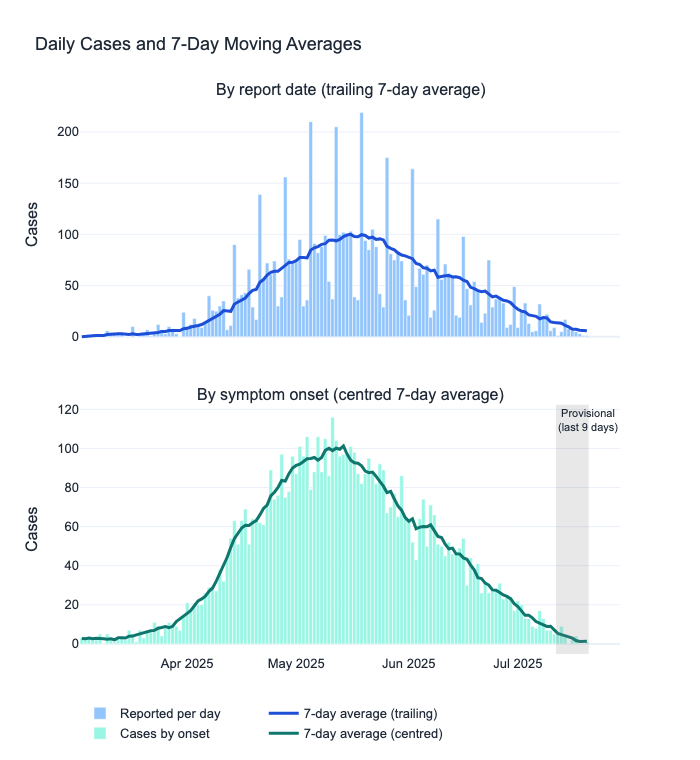

In [4]:
# Lesson 17 — Step 4: Daily epidemic curves and 7-day moving averages
import plotly.io as pio
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# House style for every chart in this lesson (applied explicitly to each figure)
pio.renderers.default = "plotly_mimetype+png"   # interactive in VS Code + PNG copy for GitHub
HOUSE = dict(
    template="plotly_white",
    font=dict(family="Arial", size=13, color="#1F2937"),
    hoverlabel=dict(bgcolor="white", bordercolor="#9CA3AF", font=dict(size=12, color="#111827")),
)

daily = q("""
WITH onset AS (
    SELECT onset_date AS date_day, count(*) AS n FROM cases_clean GROUP BY 1
),
report AS (
    SELECT report_date AS date_day, count(*) AS n FROM cases_clean
    WHERE NOT date_error GROUP BY 1
)
SELECT
    d.date_day,
    d.day_name,
    d.is_weekend,
    coalesce(o.n, 0) AS onset_cases,
    coalesce(r.n, 0) AS reported_cases,
    -- trailing 7-day average: today and the 6 days before (what a daily dashboard shows)
    round(avg(coalesce(r.n, 0)) OVER (ORDER BY d.date_day
          ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 1) AS reported_ma7,
    -- centred 7-day average: 3 days either side (for describing the epidemic by onset)
    round(avg(coalesce(o.n, 0)) OVER (ORDER BY d.date_day
          ROWS BETWEEN 3 PRECEDING AND 3 FOLLOWING), 1) AS onset_ma7
FROM dim_date AS d
LEFT JOIN onset  AS o USING (date_day)
LEFT JOIN report AS r USING (date_day)
ORDER BY d.date_day
""")

print("WHY THE CALENDAR TABLE MATTERS — days with zero onsets:")
display(q("""
SELECT dd.district,
       (SELECT count(*) FROM dim_date) - count(DISTINCT c.onset_date) AS days_with_zero_onsets
FROM dim_district AS dd
LEFT JOIN cases_clean AS c USING (district_id)
GROUP BY dd.district
ORDER BY days_with_zero_onsets DESC
LIMIT 3
"""))

print("\nREPORTING PATTERN BY WEEKDAY (average cases per day):")
weekday = (daily.assign(weekday=daily["date_day"].dt.dayofweek)
           .groupby(["weekday", "day_name"])[["onset_cases", "reported_cases"]]
           .mean().round(1).droplevel(0))
display(weekday)

delay_p95 = q("SELECT quantile_cont(report_delay_days, 0.95) AS p95 FROM cases_clean")["p95"][0]
provisional_days = int(np.ceil(delay_p95))
print(f"\n95% of cases are reported within {delay_p95:.0f} days of onset "
      f"→ the last {provisional_days} days of the onset curve are provisional.")

# --- Interactive figure: report-date curve vs onset-date curve ---
cutoff = daily["date_day"].max() - pd.Timedelta(days=provisional_days - 1)

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.10,
                    subplot_titles=("By report date (trailing 7-day average)",
                                    "By symptom onset (centred 7-day average)"))
fig.add_trace(go.Bar(x=daily["date_day"], y=daily["reported_cases"], name="Reported per day",
                     marker_color="#93C5FD", customdata=daily["day_name"],
                     hovertemplate="Reported (%{customdata}): <b>%{y}</b><extra></extra>"), row=1, col=1)
fig.add_trace(go.Scatter(x=daily["date_day"], y=daily["reported_ma7"], name="7-day average (trailing)",
                         line=dict(color="#1D4ED8", width=3),
                         hovertemplate="7-day average: <b>%{y:.1f}</b><extra></extra>"), row=1, col=1)
fig.add_trace(go.Bar(x=daily["date_day"], y=daily["onset_cases"], name="Cases by onset",
                     marker_color="#99F6E4", customdata=daily["day_name"],
                     hovertemplate="Onsets (%{customdata}): <b>%{y}</b><extra></extra>"), row=2, col=1)
fig.add_trace(go.Scatter(x=daily["date_day"], y=daily["onset_ma7"], name="7-day average (centred)",
                         line=dict(color="#0F766E", width=3),
                         hovertemplate="7-day average: <b>%{y:.1f}</b><extra></extra>"), row=2, col=1)
fig.add_vrect(x0=cutoff - pd.Timedelta(hours=12), x1=daily["date_day"].max() + pd.Timedelta(hours=12),
              fillcolor="gray", opacity=0.18, line_width=0, row=2, col=1,
              annotation_text=f"Provisional<br>(last {provisional_days} days)",
              annotation_position="top left", annotation_font_size=11)
fig.update_layout(**HOUSE, title="Daily Cases and 7-Day Moving Averages", height=760,
                  hovermode="x unified", bargap=0,
                  legend=dict(orientation="h", yanchor="top", y=-0.08, xanchor="left", x=0))
fig.update_xaxes(hoverformat="%a %d %b %Y")
fig.update_yaxes(title_text="Cases", row=1, col=1)
fig.update_yaxes(title_text="Cases", row=2, col=1)
fig.show()

ATTACK RATE BY DISTRICT, PROVINCE AND REGION (GROUP BY ROLLUP):


,province,district,cases,population,attack_rate_per_100k,hospitalised,deaths,case_fatality_pct
0,Eastern,Eastvale,1277,310000,411.9,189,29,2.27
1,Eastern,Riverbend,605,274000,220.8,95,14,2.31
2,Eastern,(province subtotal),1882,584000,322.3,284,43,2.28
3,Northern,North Ridge,712,238000,299.2,116,14,1.97
4,Northern,Hillcrest,274,187000,146.5,47,8,2.92
5,Northern,(province subtotal),986,425000,232.0,163,22,2.23
6,Urban,Central,1356,612000,221.6,206,26,1.92
7,Urban,Lakeside,990,455000,217.6,164,25,2.53
8,Urban,(province subtotal),2346,1067000,219.9,370,51,2.17
9,Western,Westfield,573,341000,168.0,84,15,2.62



CASES BY PROVINCE AND SEX, ALL SUBTOTALS (GROUP BY CUBE):


,province,sex,cases
0,Eastern,F,933
1,Eastern,M,949
2,Eastern,ALL,1882
3,Northern,F,516
4,Northern,M,470
5,Northern,ALL,986
6,Urban,F,1208
7,Urban,M,1138
8,Urban,ALL,2346
9,Western,F,375



PEAK WEEK PER DISTRICT (by onset):


,district,iso_week,week_start,cases,incidence_per_100k
0,Central,2025-W16,2025-04-14,259,42.3
1,Lakeside,2025-W18,2025-04-28,169,37.1
2,North Ridge,2025-W19,2025-05-05,151,63.4
3,Eastvale,2025-W20,2025-05-12,231,74.5
4,Riverbend,2025-W22,2025-05-26,118,43.1
5,Hillcrest,2025-W23,2025-06-02,63,33.7
6,Westfield,2025-W25,2025-06-16,104,30.5
7,Southport,2025-W26,2025-06-23,45,15.2



WEEK-OVER-WEEK GROWTH, EXAMPLE (Eastvale, weeks 6–13):


,iso_week,cases,prev_week_cases,wow_growth_pct,incidence_per_100k
25,2025-W15,15,3,<NA>,4.8
26,2025-W16,21,15,40,6.8
27,2025-W17,57,21,171,18.4
28,2025-W18,109,57,91,35.2
29,2025-W19,173,109,59,55.8
30,2025-W20,231,173,34,74.5
31,2025-W21,217,231,-6,70.0
32,2025-W22,165,217,-24,53.2


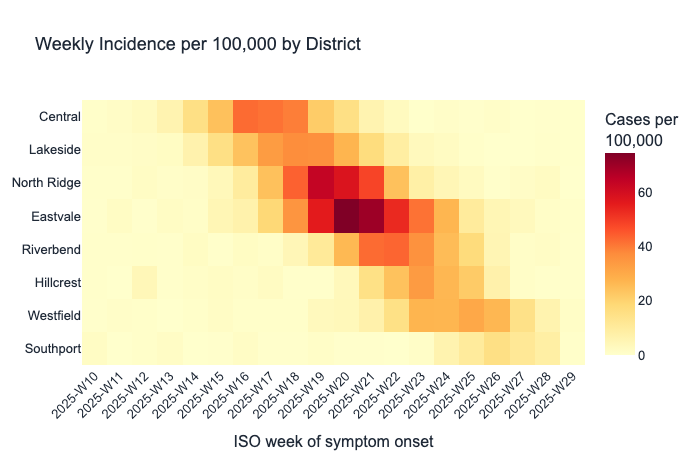

In [5]:
# Lesson 17 — Step 5: OLAP roll-ups, attack rates and week-over-week growth

# --- 5a. ROLLUP: district rows, province subtotals and a regional total in one query ---
print("ATTACK RATE BY DISTRICT, PROVINCE AND REGION (GROUP BY ROLLUP):")
display(q("""
WITH by_district AS (               -- aggregate to one row per district first
    SELECT d.province, d.district, d.population,
           count(*)                 AS cases,
           count_if(c.hospitalised) AS hospitalised,
           count_if(c.died)         AS deaths
    FROM cases_clean AS c
    JOIN dim_district AS d USING (district_id)
    GROUP BY ALL
)
SELECT
    CASE WHEN GROUPING(province) = 1 THEN '— REGION TOTAL —'
         ELSE province END                                     AS province,
    CASE WHEN GROUPING(province) = 1 THEN ''
         WHEN GROUPING(district) = 1 THEN '(province subtotal)'
         ELSE district END                                     AS district,
    sum(cases)                                                 AS cases,
    sum(population)                                            AS population,
    round(sum(cases) * 100000.0 / sum(population), 1)          AS attack_rate_per_100k,
    sum(hospitalised)                                          AS hospitalised,
    sum(deaths)                                                AS deaths,
    round(100.0 * sum(deaths) / sum(cases), 2)                 AS case_fatality_pct
FROM by_district
GROUP BY ROLLUP (province, district)
ORDER BY GROUPING(province), province, GROUPING(district), attack_rate_per_100k DESC
"""))

# --- 5b. CUBE: every combination of province and sex, including all subtotals ---
print("\nCASES BY PROVINCE AND SEX, ALL SUBTOTALS (GROUP BY CUBE):")
display(q("""
SELECT coalesce(d.province, 'ALL') AS province,
       coalesce(c.sex, 'ALL')      AS sex,
       count(*)                    AS cases
FROM cases_clean AS c
JOIN dim_district AS d USING (district_id)
GROUP BY CUBE (d.province, c.sex)
ORDER BY GROUPING(d.province), province, GROUPING(c.sex), sex
"""))

# --- 5c. Weekly incidence per 100,000 and week-over-week growth (LAG) ---
weekly = q("""
WITH grid AS (                      -- every district × every week, even with zero cases
    SELECT DISTINCT dd.district_id, dd.district, dd.population, d.week_start, d.iso_week
    FROM dim_district AS dd CROSS JOIN dim_date AS d
),
counts AS (
    SELECT district_id, CAST(date_trunc('week', onset_date) AS DATE) AS week_start,
           count(*) AS cases
    FROM cases_clean GROUP BY ALL
)
SELECT
    g.district, g.week_start, g.iso_week,
    coalesce(c.cases, 0)                                            AS cases,
    round(coalesce(c.cases, 0) * 100000.0 / g.population, 1)        AS incidence_per_100k,
    lag(coalesce(c.cases, 0)) OVER w                                AS prev_week_cases,
    -- growth only when last week had at least 10 cases (small counts give meaningless %)
    CASE WHEN lag(coalesce(c.cases, 0)) OVER w >= 10 THEN
         round(100.0 * (coalesce(c.cases, 0) - lag(coalesce(c.cases, 0)) OVER w)
               / lag(coalesce(c.cases, 0)) OVER w, 0) END             AS wow_growth_pct
FROM grid AS g
LEFT JOIN counts AS c USING (district_id, week_start)
WINDOW w AS (PARTITION BY g.district ORDER BY g.week_start)
ORDER BY g.district, g.week_start
""")

print("\nPEAK WEEK PER DISTRICT (by onset):")
peak = (weekly.loc[weekly.groupby("district")["incidence_per_100k"].idxmax(),
                   ["district", "iso_week", "week_start", "cases", "incidence_per_100k"]]
        .sort_values("week_start").reset_index(drop=True))
display(peak)

print("\nWEEK-OVER-WEEK GROWTH, EXAMPLE (Eastvale, weeks 6–13):")
display(weekly[weekly["district"] == "Eastvale"].iloc[5:13][
    ["iso_week", "cases", "prev_week_cases", "wow_growth_pct", "incidence_per_100k"]])

# --- Interactive figure: weekly incidence heatmap with hover details ---
order = peak["district"].tolist()
pivot = lambda col: weekly.pivot(index="district", columns="iso_week", values=col).loc[order]
incidence, cases_w = pivot("incidence_per_100k"), pivot("cases")
growth_txt = pivot("wow_growth_pct").map(lambda v: "n/a (under 10 cases last week)" if pd.isna(v) else f"{v:+.0f}%")
hover_data = np.dstack([cases_w.values, growth_txt.values])

fig = go.Figure(go.Heatmap(
    z=incidence.values, x=incidence.columns, y=order, customdata=hover_data,
    colorscale="YlOrRd", colorbar=dict(title="Cases per<br>100,000"),
    hovertemplate=("<b>%{y}</b> — week %{x}<br>Incidence: <b>%{z:.1f}</b> per 100,000"
                   "<br>Cases: %{customdata[0]}<br>Week-over-week: %{customdata[1]}<extra></extra>"),
))
fig.update_layout(**HOUSE, title="Weekly Incidence per 100,000 by District",
                  height=460, xaxis_title="ISO week of symptom onset")
fig.update_yaxes(autorange="reversed", showgrid=False)
fig.update_xaxes(showgrid=False, tickangle=-45)
fig.show()

## Step 6 — Surveillance Dashboard

A single-page dashboard combines headline indicators, the epidemic curve with its 7-day average, attack rates by district, the reporting-delay distribution and weekly incidence by district. It is exported as an interactive HTML page (for GitHub Pages) and a static PNG.

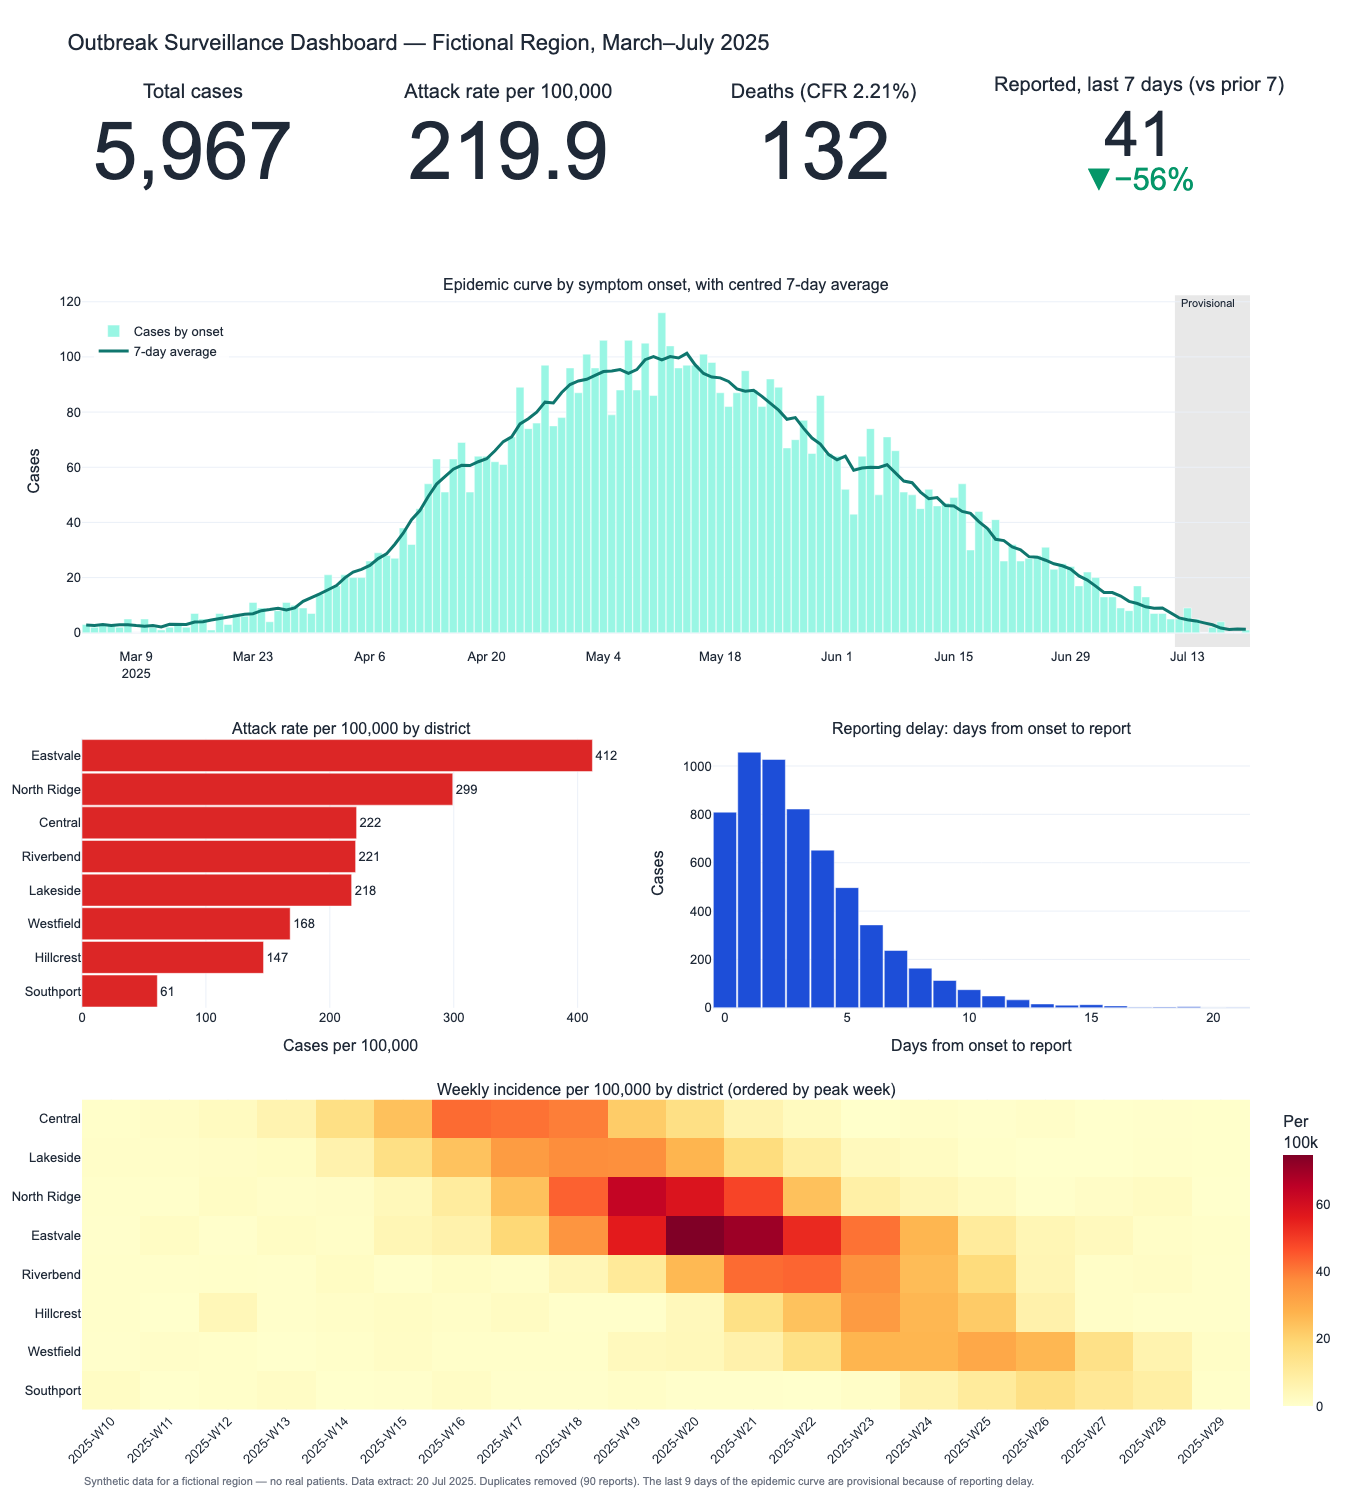

Saved: docs/surveillance_dashboard.html and figures/lesson17_surveillance_dashboard.png


In [6]:
# Lesson 17 — Step 6: Surveillance dashboard (interactive HTML + static PNG)

# --- Inputs for the dashboard, all from SQL ---
kpi = q("""
SELECT count(*)                                      AS cases,
       count_if(died)                                AS deaths,
       round(100.0 * count_if(died) / count(*), 2)   AS cfr_pct,
       round(count(*) * 100000.0 / (SELECT sum(population) FROM dim_district), 1) AS attack_rate
FROM cases_clean
""").iloc[0]
n_duplicates = int(q("SELECT count(*) - count(DISTINCT patient_id) AS n FROM fact_cases")["n"][0])

last7 = int(daily["reported_cases"].tail(7).sum())
prev7 = int(daily["reported_cases"].iloc[-14:-7].sum())

by_district = q("""
SELECT d.district, d.province, d.population, count(*) AS cases,
       round(count(*) * 100000.0 / d.population, 1) AS attack_rate
FROM cases_clean AS c JOIN dim_district AS d USING (district_id)
GROUP BY d.district, d.province, d.population
ORDER BY attack_rate
""")

delays = q("""
SELECT report_delay_days AS delay, count(*) AS cases
FROM cases_clean WHERE report_delay_days IS NOT NULL
GROUP BY 1 ORDER BY 1
""")
delays = delays[delays["delay"] <= 21]

# --- Layout: KPI row, epidemic curve, two panels, heatmap ---
dash = make_subplots(
    rows=4, cols=4,
    specs=[[{"type": "indicator"}] * 4,
           [{"colspan": 4}, None, None, None],
           [{"colspan": 2}, None, {"colspan": 2}, None],
           [{"colspan": 4}, None, None, None]],
    row_heights=[0.10, 0.34, 0.26, 0.30], vertical_spacing=0.07, horizontal_spacing=0.08,
    subplot_titles=["", "", "", "",
                    "Epidemic curve by symptom onset, with centred 7-day average",
                    "Attack rate per 100,000 by district", "Reporting delay: days from onset to report",
                    "Weekly incidence per 100,000 by district (ordered by peak week)"],
)

# Row 1 — KPI cards
dash.add_trace(go.Indicator(mode="number", value=int(kpi["cases"]), number=dict(valueformat=","),
                            title=dict(text="Total cases")), row=1, col=1)
dash.add_trace(go.Indicator(mode="number", value=float(kpi["attack_rate"]), number=dict(valueformat=".1f"),
                            title=dict(text="Attack rate per 100,000")), row=1, col=2)
dash.add_trace(go.Indicator(mode="number", value=int(kpi["deaths"]),
                            title=dict(text=f"Deaths (CFR {kpi['cfr_pct']:.2f}%)")), row=1, col=3)
dash.add_trace(go.Indicator(mode="number+delta", value=last7,
                            delta=dict(reference=prev7, relative=True, valueformat=".0%",
                                       increasing=dict(color="#DC2626"), decreasing=dict(color="#059669")),
                            title=dict(text="Reported, last 7 days (vs prior 7)")),
               row=1, col=4)

# Row 2 — epidemic curve with 7-day average and provisional zone
dash.add_trace(go.Bar(x=daily["date_day"], y=daily["onset_cases"], name="Cases by onset",
                      marker_color="#99F6E4", customdata=daily["day_name"],
                      hovertemplate="%{x|%d %b %Y} (%{customdata})<br>Onsets: <b>%{y}</b><extra></extra>"),
               row=2, col=1)
dash.add_trace(go.Scatter(x=daily["date_day"], y=daily["onset_ma7"], name="7-day average",
                          line=dict(color="#0F766E", width=3),
                          hovertemplate="%{x|%d %b %Y}<br>7-day average: <b>%{y:.1f}</b><extra></extra>"),
               row=2, col=1)
# Shaded provisional zone, drawn on the epidemic-curve axes (x / y domain)
dash.add_shape(type="rect", xref="x", yref="y domain",
               x0=cutoff - pd.Timedelta(hours=12), x1=daily["date_day"].max() + pd.Timedelta(hours=12),
               y0=0, y1=1, fillcolor="gray", opacity=0.18, line_width=0, layer="below")
dash.add_annotation(xref="x", yref="y domain", x=cutoff, y=1, text="Provisional",
                    showarrow=False, xanchor="left", yanchor="top", font=dict(size=11))

# Row 3 — attack rate by district, and reporting delay distribution
dash.add_trace(go.Bar(x=by_district["attack_rate"], y=by_district["district"], orientation="h",
                      marker_color="#DC2626", text=by_district["attack_rate"], texttemplate="%{text:.0f}",
                      textposition="outside", customdata=by_district[["province", "cases"]],
                      hovertemplate=("<b>%{y}</b> (%{customdata[0]})<br>Attack rate: <b>%{x:.1f}</b> per 100,000"
                                     "<br>Cases: %{customdata[1]:,}<extra></extra>"), showlegend=False),
               row=3, col=1)
dash.add_trace(go.Bar(x=delays["delay"], y=delays["cases"], marker_color="#1D4ED8", showlegend=False,
                      hovertemplate="Reported after <b>%{x} days</b>: %{y:,} cases<extra></extra>"),
               row=3, col=3)

# Row 4 — weekly incidence heatmap
dash.add_trace(go.Heatmap(z=incidence.values, x=incidence.columns, y=order, customdata=hover_data,
                          colorscale="YlOrRd", colorbar=dict(title="Per<br>100k", len=0.24, y=0.115),
                          hovertemplate=("<b>%{y}</b> — week %{x}<br>Incidence: <b>%{z:.1f}</b> per 100,000"
                                         "<br>Cases: %{customdata[0]}<br>Week-over-week: %{customdata[1]}"
                                         "<extra></extra>")),
               row=4, col=1)

dash.update_layout(**HOUSE, height=1500, bargap=0.05,
                   title=dict(text="Outbreak Surveillance Dashboard — Fictional Region, March–July 2025",
                              font=dict(size=22)),
                   legend=dict(orientation="v", yanchor="top", y=0.835, xanchor="left", x=0.01,
                               bgcolor="rgba(255,255,255,0.8)"),
                   margin=dict(l=80, r=40, t=100, b=90))
dash.update_xaxes(title_text="Days from onset to report", row=3, col=3)
dash.update_xaxes(title_text="Cases per 100,000", row=3, col=1)
dash.update_yaxes(title_text="Cases", row=2, col=1)
dash.update_yaxes(title_text="Cases", row=3, col=3)
dash.update_yaxes(autorange="reversed", row=4, col=1)
dash.update_xaxes(tickangle=-45, row=4, col=1)
dash.add_annotation(text=(f"Synthetic data for a fictional region — no real patients. Data extract: "
                          f"{extract_date:%d %b %Y}. Duplicates removed ({n_duplicates} reports). The last "
                          f"{provisional_days} days of the epidemic curve are provisional because of reporting delay."),
                    xref="paper", yref="paper", x=0, y=-0.06, showarrow=False, align="left",
                    font=dict(size=11, color="#6B7280"))

# Show at full width inside the notebook, then restore automatic width for the HTML page
dash.update_layout(width=1350)
dash.show()
dash.update_layout(width=None)

# --- Save: interactive HTML for GitHub Pages, static PNG for the README ---
docs_dir = repo_root / "docs"
docs_dir.mkdir(exist_ok=True)
dash.write_html(docs_dir / "surveillance_dashboard.html", include_plotlyjs="cdn",
                config={"displaylogo": False, "responsive": True})
dash.write_image(repo_root / "figures" / "lesson17_surveillance_dashboard.png",
                 width=1400, height=1500, scale=2)
print("Saved: docs/surveillance_dashboard.html and figures/lesson17_surveillance_dashboard.png")

## Conclusions

1. **Data quality first.** Of 6,057 case reports, 90 were duplicate reports of the same patient (removed with a `QUALIFY ROW_NUMBER()` window) and 30 had a report date before symptom onset (flagged and excluded from delay statistics), leaving 5,967 unique cases.
2. **The calendar dimension matters.** Southport had no new onsets on 83 of 140 days. Without a calendar table, those zero days disappear from `GROUP BY` results, and moving averages are computed over the wrong days.
3. **Reporting artefacts are large.** Onsets were steady across the week (about 39–46 per day), but reports averaged 92 on Mondays and about 17 on weekend days. The trailing 7-day average removes this weekly pattern. Because 95% of cases were reported within 9 days of onset, the last 9 days of the onset curve are provisional.
4. **Rates, not counts, show risk.** Central had the most cases (1,356), but Eastvale had the highest attack rate (412 per 100,000), almost double the regional rate of 220.
5. **The outbreak spread outward over ten weeks,** from Central (peak in ISO week 16) to Southport (week 26). Week-over-week growth in Eastvale fell steadily from +171% to +34% before turning negative. Slowing growth is an early signal that the peak is near.

**Limitations:** synthetic data for a fictional region; the reporting-delay and duplication patterns are simulated, not measured.

### SQL dialect reference: DuckDB, ClickHouse and Snowflake

| Task | DuckDB (this lesson) | ClickHouse | Snowflake |
|---|---|---|---|
| Query Parquet files | `read_parquet('file.parquet')` | `file('file.parquet', Parquet)` or `s3(...)` | External table, or `COPY INTO` from a stage |
| Calendar of dates | `range(DATE '2025-03-03', DATE '2025-07-21', INTERVAL 1 DAY)` | `toDate('2025-03-03') + number FROM numbers(140)` | `DATEADD(day, SEQ4(), '2025-03-03') FROM TABLE(GENERATOR(ROWCOUNT => 140))` |
| Start of week | `date_trunc('week', d)` | `toMonday(d)` | `DATE_TRUNC('WEEK', d)` |
| Conditional count | `count_if(cond)` | `countIf(cond)` | `COUNT_IF(cond)` |
| Keep first row per patient | `QUALIFY row_number() OVER (...) = 1` | `ORDER BY ... LIMIT 1 BY patient_id` | `QUALIFY ROW_NUMBER() OVER (...) = 1` |
| 7-day moving average | `avg(x) OVER (ORDER BY d ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)` | Same window syntax | Same window syntax |
| Previous week's value | `lag(x) OVER (PARTITION BY district ORDER BY week)` | `lagInFrame(x) OVER (...)` | `LAG(x) OVER (...)` |
| Subtotals | `GROUP BY ROLLUP (a, b)` / `CUBE (a, b)` | `GROUP BY a, b WITH ROLLUP` / `WITH CUBE` | `GROUP BY ROLLUP (a, b)` / `CUBE (a, b)` |
| Days between dates | `date_diff('day', a, b)` | `dateDiff('day', a, b)` | `DATEDIFF(day, a, b)` |